### Resizing, Cropping, Rotation, Flipping, Brightness Adjustment, Contrast Adjustment, Grayscale Conversion, Thresholding
### Blur, Gaussian Blur, Edge Detection

In [45]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

**توضیحات کد:**
در این بخش، کتابخانه‌های اصلی مورد نیاز برای انجام عملیات‌های پایه پردازش تصویر فراخوانی شده‌اند:
- **`cv2` (OpenCV):** برای خواندن تصویر و اعمال تبدیل‌های هندسی و پردازشی (تغییر اندازه، چرخش، قرینه‌سازی، فیلترگذاری و غیره).
- **`numpy` (با نام مستعار `np`):** برای کار با آرایه‌های چندبعدی و انجام محاسبات ماتریسی روی پیکسل‌های تصویر.
- **`matplotlib.pyplot` (با نام مستعار `plt`):** برای رسم و نمایش تصاویر و مقایسه بصری خروجی‌ها در محیط نوت‌بوک.


In [46]:
image_path = r"/run/media/amin-maky/LinuxFiles/CVPrjs/Learning-Lab/Hardware-Engineering-Sandbox/Python-Sandbox/ipynb/DIP-HW/HW-1/Me.jpg"
image = cv2.imread(image_path)

print(image.shape)
print(image.dtype)

(736, 736, 3)
uint8


**توضیحات کد و خروجی:**
- در این سلول، مسیر فایل تصویر در متغیر `image_path` تعریف شده و تصویر با تابع `cv2.imread()` در متغیر `image` بارگذاری شده است.
- خروجی `image.shape` مقدار `(736, 736, 3)` را نشان می‌دهد که بیانگر ارتفاع ۷۳۶ پیکسل، عرض ۷۳۶ پیکسل و ۳ کانال رنگی (BGR) است.
- خروجی `image.dtype` مقدار `uint8` را برمی‌گرداند که نشان می‌دهد شدت روشنایی هر زیرپیکسل به صورت عدد صحیح ۸ بیتی بدون علامت (در بازه `0` تا `255`) ذخیره شده است.


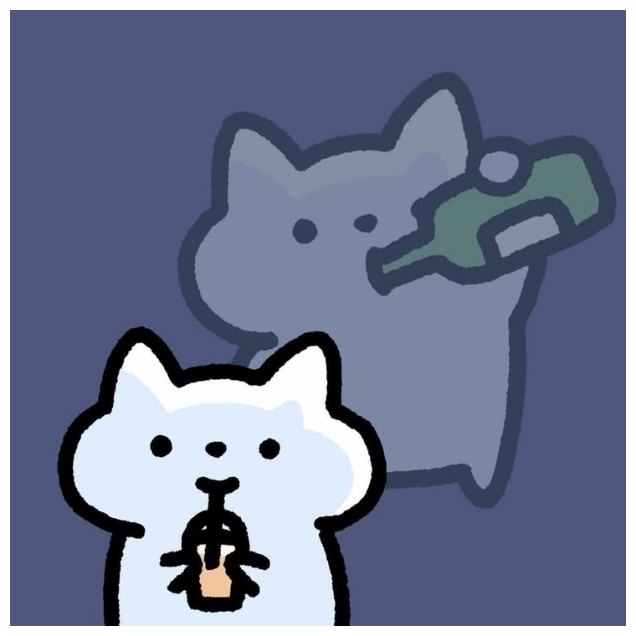

In [47]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

**توضیحات کد و خروجی:**
- از آنجا که کتابخانه OpenCV تصویر را با ترتیب کانال‌های `BGR` می‌خواند ولی Matplotlib انتظار ترتیب `RGB` را دارد، ابتدا با دستور `cv2.cvtColor(image, cv2.COLOR_BGR2RGB)` فضای رنگی تصویر اصلاح شده است.
- سپس با تعیین ابعاد بوم (`figsize=(8, 8)`) و حذف محورهای مختصات (`plt.axis("off")`)، تصویر اصلی با رنگ‌های واقعی خود نمایش داده شده است.


### Image Resizing

In [48]:
resized = cv2.resize(image, (500, 500))

print("Original:", image.shape)
print("Resized:", resized.shape)

Original: (736, 736, 3)
Resized: (500, 500, 3)


**توضیحات کد و خروجی:**
- تابع `cv2.resize(image, (500, 500))` ابعاد تصویر ورودی را به اندازه جدید `(عرض=500، ارتفاع=500)` تغییر می‌دهد.
- همان‌طور که در خروجی متنی مشخص است، ابعاد تصویر از `(736, 736, 3)` به `(500, 500, 3)` کاهش یافته اما تعداد کانال‌های رنگی (`3`) ثابت مانده است.


### Image Cropping

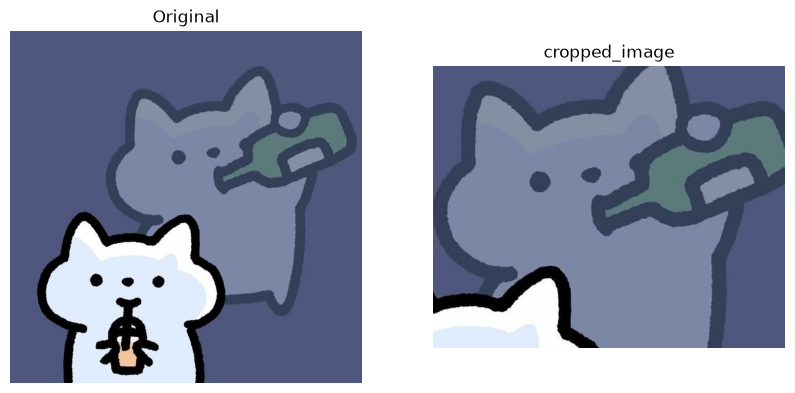

In [49]:
crop = image[100:500, 200:700]
crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(crop_rgb)
plt.title("cropped_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- در خط اول، با استفاده از برش آرایه‌ای (Slicing) به صورت `image[100:500, 200:700]`، ناحیه‌ای از سطر ۱۰۰ تا ۵۰۰ (ارتفاع ۴۰۰ پیکسل) و ستون ۲۰۰ تا ۷۰۰ (عرض ۵۰۰ پیکسل) از تصویر اصلی جدا شده است.
- پس از تبدیل فضای رنگیِ بخش برش‌خورده به `RGB`، با استفاده از `plt.subplot(1, 2, ...)` تصویر اصلی و تصویر برش‌خورده (`cropped_image`) در یک سطر و دو ستون در کنار هم نمایش داده شده‌اند تا ناحیه انتخاب‌شده به وضوح با تصویر مرجع مقایسه شود.


### Image Rotation

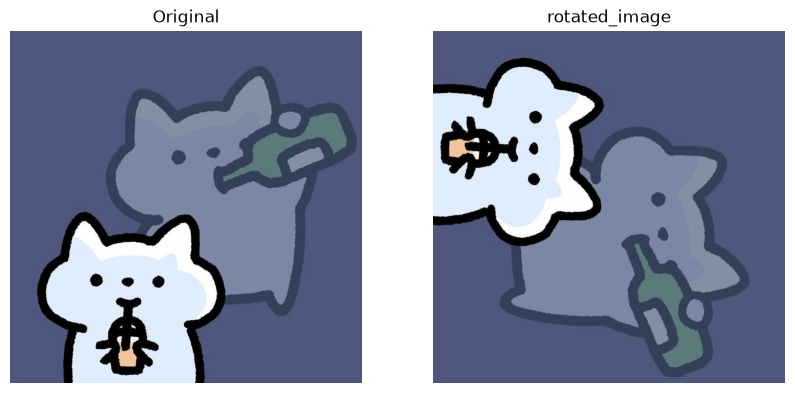

In [50]:
rotated = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
rotated_rgb = cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_rgb)
plt.title("rotated_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- تابع `cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)` تصویر ورودی را به اندازه **۹۰ درجه در جهت عقربه‌های ساعت (ساعت‌گرد)** می‌چرخاند.
- پس از تبدیل تصویر چرخش‌یافته به فرمت `RGB`، تصویر اصلی و تصویر چرخیده در کنار هم رسم شده‌اند.


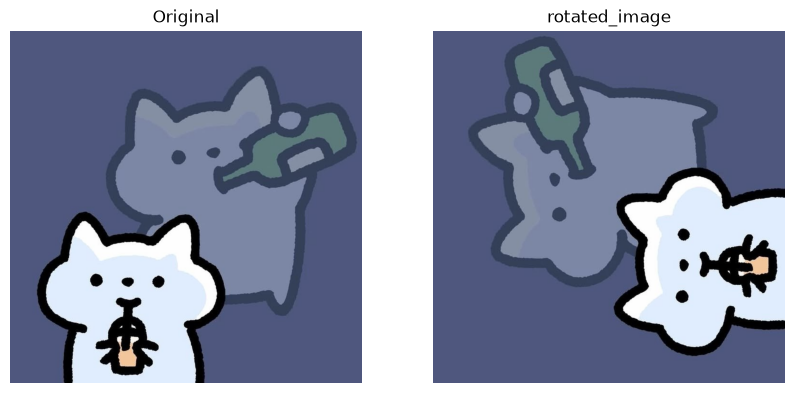

In [51]:
rotated = cv2.rotate(image, cv2.ROTATE_90_COUNTERCLOCKWISE)
rotated_rgb = cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_rgb)
plt.title("rotated_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- در این سلول، با استفاده از پرچم `cv2.ROTATE_90_COUNTERCLOCKWISE` در تابع `cv2.rotate()`، تصویر به اندازه **۹۰ درجه خلاف جهت عقربه‌های ساعت (پادساعت‌گرد)** چرخانده شده و در کنار تصویر اصلی به نمایش درآمده است.


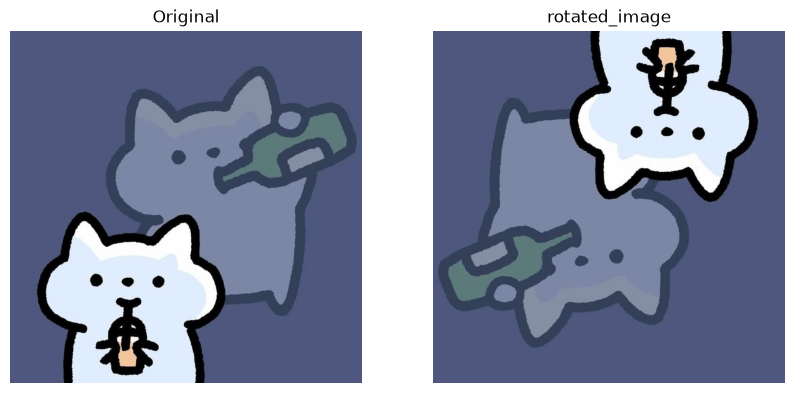

In [52]:
rotated = cv2.rotate(image, cv2.ROTATE_180)
rotated_rgb = cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_rgb)
plt.title("rotated_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- با قرار دادن پرچم `cv2.ROTATE_180` در تابع `cv2.rotate()`، تصویر به اندازه **۱۸۰ درجه** چرخانده شده (کاملاً وارونه شده) و پس از تبدیل به فضای رنگی `RGB` در کنار تصویر اصلی نمایش داده شده است.


### Image Flipping

#### Horizontal Flip
#### Left ↔ Right

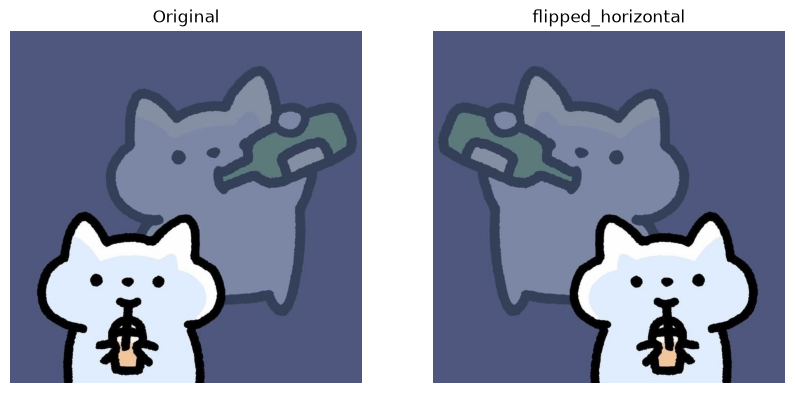

In [53]:
flipped_horizontal = cv2.flip(image, 1)
flipped_horizontal_rgb = cv2.cvtColor(flipped_horizontal, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(flipped_horizontal_rgb)
plt.title("flipped_horizontal")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- تابع `cv2.flip(image, flipCode)` برای قرینه‌سازی (آینه‌ای کردن) تصویر استفاده می‌شود.
- قرار دادن `flipCode = 1` باعث **قرینه‌سازی افقی (Horizontal Flip)** حول محور عمودی می‌شود؛ یعنی سمت چپ و راست تصویر جابه‌جا می‌شوند (تصویر آینه‌ای). در خروجی، تصویر اصلی و تصویر قرینه‌شده افقی در کنار هم نمایش داده شده‌اند.


#### Vertical Flip
#### Top ↔ Bottom

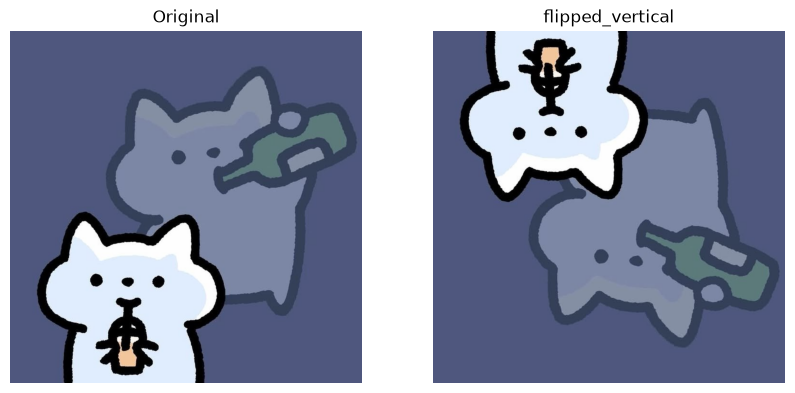

In [54]:
flipped_vertical = cv2.flip(image, 0)
flipped_vertical_rgb = cv2.cvtColor(flipped_vertical, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(flipped_vertical_rgb)
plt.title("flipped_vertical")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- قرار دادن `flipCode = 0` در تابع `cv2.flip(image, 0)` باعث **قرینه‌سازی عمودی (Vertical Flip)** تصویر حول محور افقی می‌شود؛ به طوری که بخش بالایی و پایینی تصویر با یکدیگر جابه‌جا می‌شوند.
- پس از تبدیل فضای رنگی به `RGB`، تصویر اصلی و تصویر قرینه‌شده عمودی در کنار هم نمایش داده شده‌اند.


#### Flip Along Both Axes

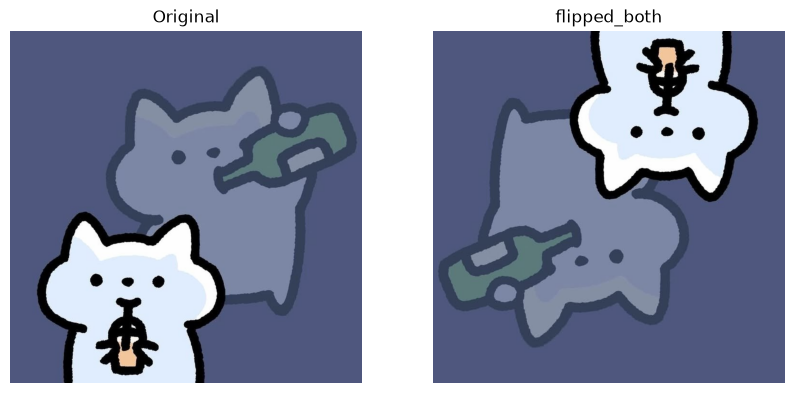

In [55]:
flipped_both = cv2.flip(image, -1)
flipped_both_rgb = cv2.cvtColor(flipped_both, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(flipped_both_rgb)
plt.title("flipped_both")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- قرار دادن مقدار منفی (`flipCode = -1`) در تابع `cv2.flip(image, -1)` باعث می‌شود تصویر **هم به صورت افقی و هم به صورت عمودی** (نسبت به هر دو محور) قرینه شود که از نظر هندسی معادل چرخش ۱۸۰ درجه‌ای تصویر است.


### Brightness Adjustment
Saturation and Pixel Value Clipping

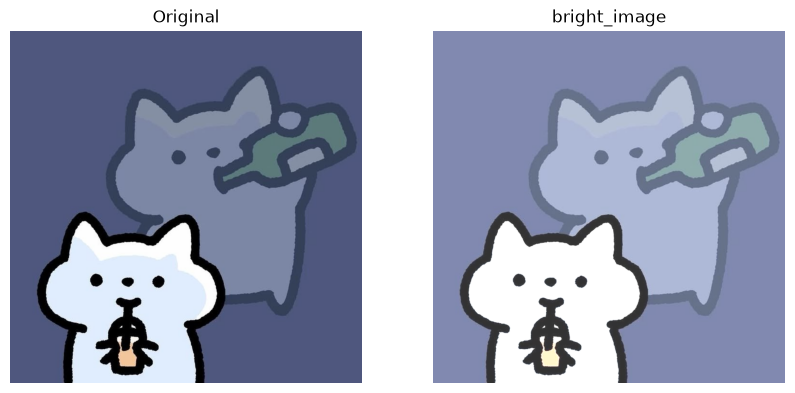

In [56]:
bright = cv2.add(image, 50)
bright_rgb = cv2.cvtColor(bright, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(bright_rgb)
plt.title("bright_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- در این سلول، با استفاده از تابع `cv2.add(image, 50)` مقدار ثابت `50` به شدت روشنایی (کانال‌های رنگی) پیکسل‌های تصویر اضافه شده است تا تصویر روشن‌تر (`bright_image`) شود.
- **نکته مهم (Saturation / Clipping):** مزیت استفاده از `cv2.add` نسبت به جمع معمولی NumPy (`image + 50`) این است که OpenCV عملیات **اشباع (Saturation)** را انجام می‌دهد؛ یعنی اگر حاصل جمع پیکسلی از `255` بیشتر شود، روی عدد `255` برش (Clip) می‌خورد و دچار سرریز (Overflow و برگشت به اعداد نزدیک صفر) نمی‌شود.


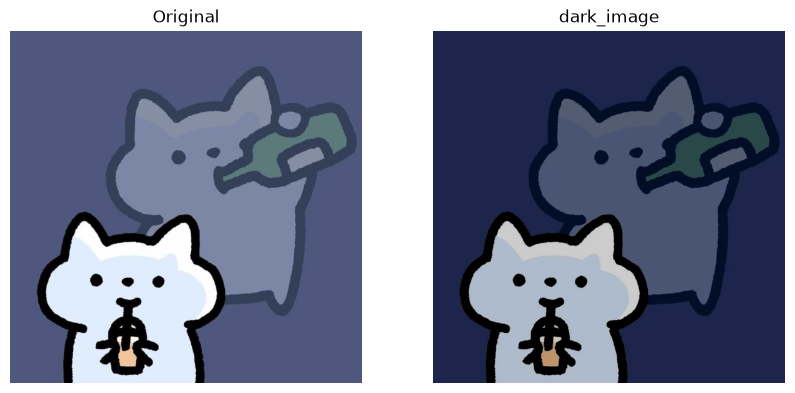

In [57]:
dark = cv2.subtract(image, 50)
dark_rgb = cv2.cvtColor(dark, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(dark_rgb)
plt.title("dark_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- تابع `cv2.subtract(image, 50)` مقدار `50` واحد از شدت روشنایی پیکسل‌های تصویر کم می‌کند و باعث تاریک‌تر شدن تصویر (`dark_image`) می‌شود.
- در این تابع نیز ویژگی **Clipping** برقرار است؛ یعنی اگر حاصل تفریق کمتر از صفر شود، مقدار پیکسل روی `0` (سیاه مطلق) ثابت می‌ماند و دچار Underflow نمی‌شود.


### Contrast Adjustment
کنتراست نشان می‌دهد تفاوت بین نواحی روشن و تاریک تصویر چقدر است

alpha = 1.5 : increase contrast    alpha = 0.7 : decrease contrast

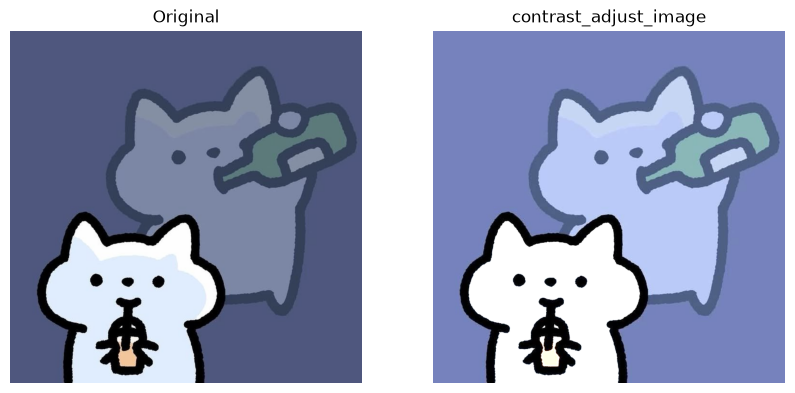

In [58]:
contrast = cv2.convertScaleAbs(image, alpha=1.5, beta=0)  # alpha → Contrast and beta  → Brightness
contrast_rgb = cv2.cvtColor(contrast, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast_rgb)
plt.title("contrast_adjust_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- تابع `cv2.convertScaleAbs(image, alpha=1.5, beta=0)` رابطه‌ی خطی $g(x) = \alpha \cdot f(x) + \beta$ را روی تک‌تک پیکسل‌ها اعمال کرده، قدرمطلق گرفته و خروجی را به نوع `uint8` (بازه ۰ تا ۲۵۵) تبدیل می‌کند.
- پارامتر `alpha` ضریب **کنتراست (Contrast)** و پارامتر `beta` مقدار **روشنایی (Brightness)** است. در اینجا با قرار دادن `alpha = 1.5` (بزرگ‌تر از ۱) و `beta = 0`، اختلاف بین نواحی تیره و روشن بیشتر شده و کنتراست تصویر افزایش یافته است.


### Brightness and Contrast Adjustment

New Pixel = alpha × Old Pixel + beta

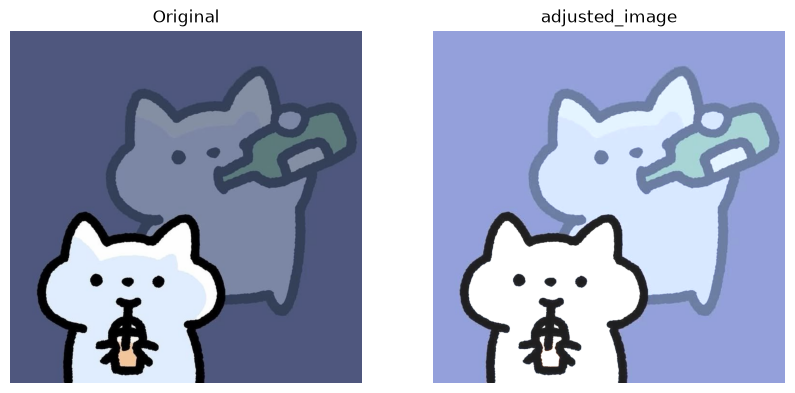

In [59]:
result = cv2.convertScaleAbs(
    image,
    alpha=1.5,
    beta=30
)

result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result_rgb)
plt.title("adjusted_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- در این سلول، با استفاده از تابع `cv2.convertScaleAbs(image, alpha=1.5, beta=30)` به صورت هم‌زمان کنتراست و روشنایی تصویر تغییر داده شده است.
- مقدار هر پیکسل جدید از فرمول $\text{New Pixel} = 1.5 \times \text{Old Pixel} + 30$ محاسبه می‌شود؛ یعنی ابتدا کنتراست با ضریب `1.5` تقویت شده و سپس کل تصویر به اندازه `30` واحد روشن‌تر شده است.


### Grayscale Conversion

(736, 736, 3)
(736, 736)


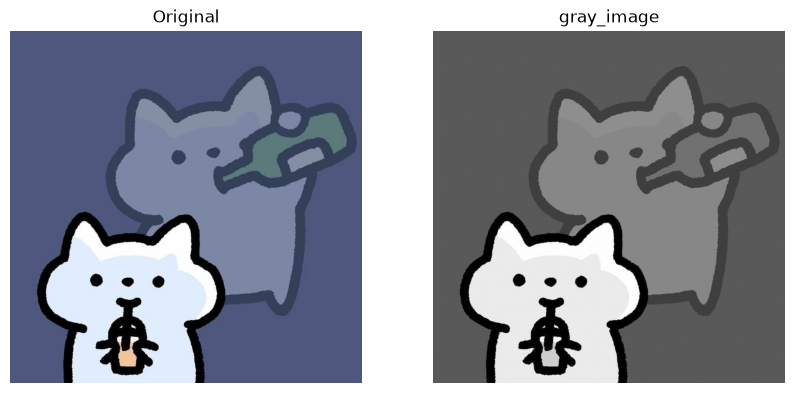

In [60]:
gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

print(image.shape)
print(gray.shape)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("gray_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- در این روش، تصویر مستقیماً در هنگام بارگذاری از دیسک با استفاده از پرچم `cv2.IMREAD_GRAYSCALE` در تابع `cv2.imread()` به صورت تک‌کاناله (سطح خاکستری) خوانده شده است.
- مقایسه خروجی `shape` نشان می‌دهد که تصویر اصلی دارای ابعاد `(736, 736, 3)` (سه‌کاناله) و تصویر خاکستری دارای ابعاد `(736, 736)` (دوبعدی و فاقد بُعد سوم کانال‌ها) است. همچنین برای نمایش صحیح آن در Matplotlib از نگاشت رنگی `cmap="gray"` استفاده شده است.


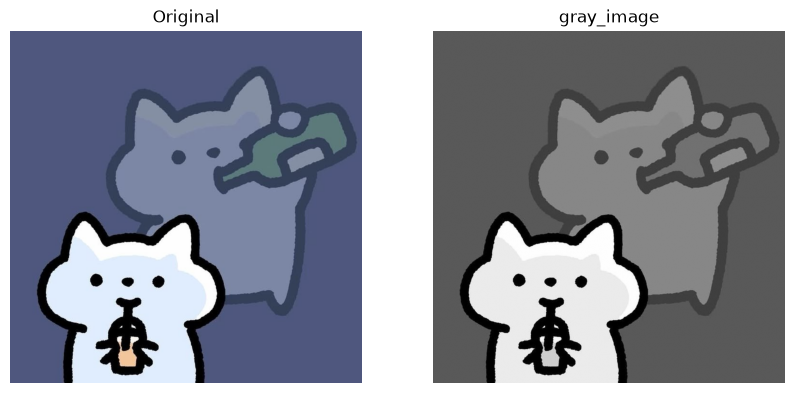

In [61]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("gray_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- برخلاف سلول قبل که تصویر را از ابتدا خاکستری می‌خواند، در این سلول تصویر رنگی موجود در حافظه (`image`) با استفاده از تابع `cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)` از فضای رنگی ۳ کاناله `BGR` به فضای تک‌کاناله خاکستری (`Grayscale`) تبدیل شده و در کنار تصویر اصلی نمایش داده شده است.


### Image Thresholding

Dark pixels  → Black

Bright pixels → White

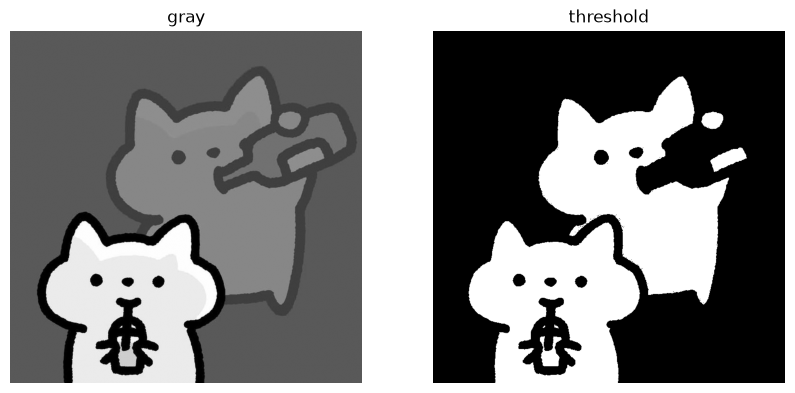

In [62]:
gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
_, threshold = cv2.threshold(gray,127,255,cv2.THRESH_BINARY)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("gray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(threshold, cmap="gray")
plt.title("threshold")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- در این بخش، ابتدا تصویر به صورت سطح خاکستری (`gray`) خوانده شده و سپس عملیات **آستانه‌گذاری دودویی (Binary Thresholding)** با دستور `cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)` روی آن اعمال شده است.
- در این روش، شدت روشنایی هر پیکسل با مقدار آستانه (`127`) مقایسه می‌شود:
  - اگر مقدار پیکسل **بیشتر از ۱۲۷** (روشن) باشد، مقدار آن به حداکثر یعنی **`255` (سفید مطلق)** تغییر می‌کند.
  - اگر مقدار پیکسل **کمتر یا مساوی ۱۲۷** (تیره) باشد، مقدار آن به **`0` (سیاه مطلق)** تبدیل می‌شود.
- خروجی، یک تصویر باینری (سیاه و سفید) است که نواحی روشن تصویر (مانند گربه‌ها) را به خوبی از پس‌زمینه تیره جدا کرده است.


### Image Blurring

Kernel size = (5,5)

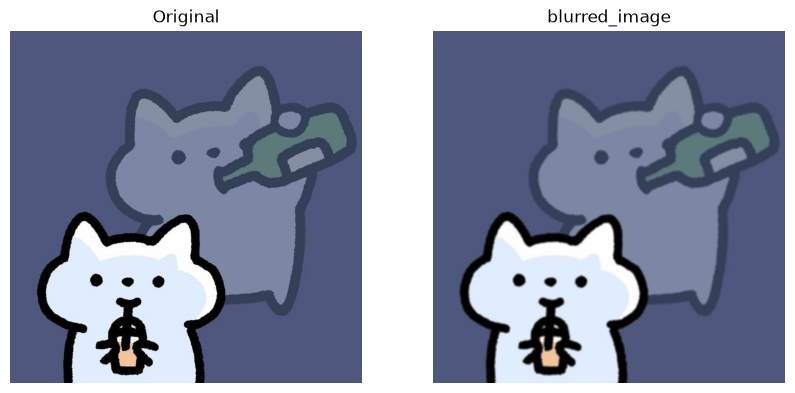

In [63]:
blurred = cv2.blur(image, (5, 5))
blurred_rgb = cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred_rgb)
plt.title("blurred_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- تابع `cv2.blur(image, (5, 5))` یک فیلتر میانگین‌گیر (Average / Box Filter) با پنجره (کرنل) به ابعاد $5 \times 5$ روی تصویر اعمال می‌کند.
- در این روش، مقدار هر پیکسل با میانگین حسابی ۲۵ پیکسل موجود در همسایگی $5 \times 5$ خودش جایگزین می‌شود که باعث نرم شدن (Smoothing)، کاهش نویز و تار شدن لبه‌های تیز تصویر (`blurred_image`) می‌گردد.


#### Gaussian Blurring

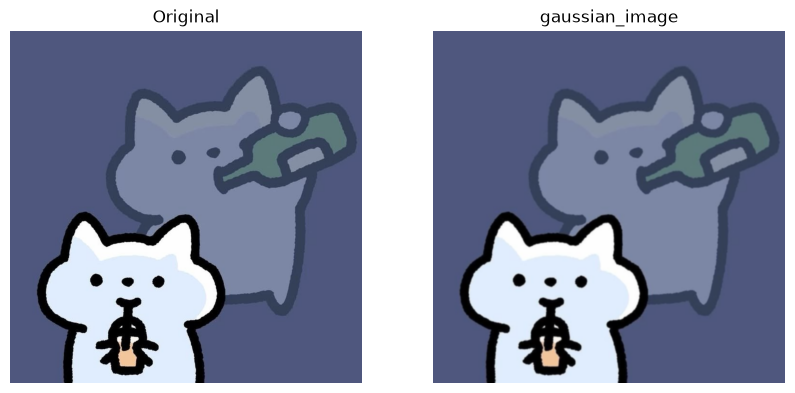

In [64]:
gaussian = cv2.GaussianBlur(image, (5, 5), 0)
gaussian_rgb = cv2.cvtColor(gaussian, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gaussian_rgb)
plt.title("gaussian_image")
plt.axis("off")

plt.show()

**توضیحات کد و خروجی:**
- تابع `cv2.GaussianBlur(image, (5, 5), 0)` به جای میانگین‌گیری ساده، از یک کرنل وزندار با توزیع نرمال (گوسی) به ابعاد $5 \times 5$ استفاده می‌کند (مقدار `0` در آرگومان سوم باعث می‌شود انحراف معیار $\sigma$ به صورت خودکار بر اساس ابعاد کرنل محاسبه شود).
- در فیلتر گوسی، پیکسل‌های نزدیک به مرکز پنجره وزن بیشتری نسبت به پیکسل‌های دورتر دارند؛ به همین دلیل تاری ایجادشده طبیعی‌تر است و ساختار کلی لبه‌ها بهتر از `cv2.blur` حفظ می‌شود.


### Edge Detection
#### Canny Edge Detection

لبه جایی است که شدت تصویر به‌طور قابل توجهی تغییر می‌کند

In [65]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(
    gray,
    100,
    200
)

**توضیحات کد:**
- در این سلول، ابتدا تصویر رنگی به سطح خاکستری (`gray`) تبدیل شده و سپس الگوریتم تشخیص لبه کَنی با دستور `cv2.Canny(gray, 100, 200)` روی آن اجرا شده است.
- اعداد `100` و `200` به ترتیب آستانه پایین (`threshold1`) و آستانه بالا (`threshold2`) برای فرآیند Hysteresis Thresholding هستند: گرادیان‌های بزرگ‌تر از `200` به عنوان لبه قوی پذیرفته می‌شوند، گرادیان‌های کمتر از `100` حذف می‌شوند و مقادیر بین این دو تنها در صورتی که به یک لبه قوی متصل باشند، به عنوان لبه در نظر گرفته می‌شوند.


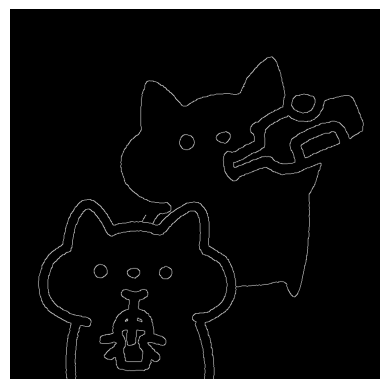

In [66]:
plt.imshow(edges, cmap="gray")
plt.axis("off")
plt.show()

**توضیحات کد و خروجی:**
- در این سلول، خروجی الگوریتم Canny (`edges`) با استفاده از نگاشت رنگی خاکستری (`cmap="gray"`) نمایش داده شده است.
- خروجی یک تصویر باینری است که در آن نواحی دارای تغییرات ناگهانی شدت روشنایی (مرزها و خطوط دور گربه‌ها و بطری) با خطوط سفید (`255`) و نواحی یکنواخت با رنگ سیاه (`0`) مشخص شده‌اند.
